# 04 · EDA avanzado, transformación y visualización (IA, Unidades 1 y 2)

| ID del enunciado | Qué cubre | Sección |
|---|---|---|
| **IA1.2** / **IA1.E1** | Preprocesamiento y EDA: univariado, bivariado, multivariado y segmentos | 1 |
| **IA2.1** / **IA2.2** | Manipulación con Pandas (merge, melt/pivot, apply/map, cut/qcut, groupby, assign, pipe) y equivalente en dplyr | 2 |
| **IA2.3** | Visualización con Matplotlib, Seaborn y ggplot2 (plotnine) | 3 |
| **IA2.E1** | Patrones y correlaciones (Pearson, Spearman, V de Cramér) y 5 hallazgos | 4 |
| **IA2.5** | Detección (IQR, z-score) y tratamiento (capping p1-p99) de atípicos | 5 |
| **IA2.4** | Normalización, estandarización y PCA | 6 |
| **IA1.E2** / **IA2.E2** | Variables relevantes y optimización del preprocesamiento | 7 |

Se trabaja sobre `db/processed/train.csv` (limpio, sin nulos ni duplicados, generado por el notebook 03). Todo el análisis se hace en **train** para no mirar el conjunto de prueba.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def buscar_raiz(inicio: Path = Path.cwd()) -> Path:
    """Sube por los directorios hasta encontrar db/credit_risk.csv (rutas relativas, sin rutas absolutas)."""
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "db" / "credit_risk.csv").exists():
            return carpeta
    raise FileNotFoundError("No se encontró db/credit_risk.csv; ejecute el notebook desde Back/notebooks/")

PROJECT_ROOT = buscar_raiz()
RAW_DATA_PATH = PROJECT_ROOT / "db" / "credit_risk.csv"      # equivalente a config.DATA_PATH
PROCESSED_DIR = PROJECT_ROOT / "db" / "processed"
TARGET, ID_COL, TEXT_COL = "default", "id_cliente", "texto_solicitud"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.options.display.max_columns = 50
pd.options.display.width = 160
pd.options.display.float_format = "{:,.3f}".format
print("Raíz del proyecto (relativa al notebook):", Path("..", "..").as_posix())

Raíz del proyecto (relativa al notebook): ../..


In [2]:
import json
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif

df = pd.read_csv(PROCESSED_DIR / "train.csv")
with open(PROCESSED_DIR / "feature_list.json", encoding="utf-8") as f:
    FL = json.load(f)
NUM = ["edad", "antiguedad_laboral_anios", "personas_a_cargo", "ingreso_mensual", "monto_credito", "plazo_meses",
       "tasa_interes_anual", "num_creditos_activos", "moras_ultimos_12m", "relacion_deuda_ingreso", "puntaje_buro",
       "uso_cupo_tarjetas", "cuota_estimada", "ratio_cuota_ingreso", "ratio_monto_ingreso", "longitud_texto"]
CAT = ["sexo", "estado_civil", "nivel_educativo", "situacion_laboral", "tipo_vivienda", "proposito", "rango_edad", "tiene_moras_previas"]
ORDEN_EDU = ["Primaria", "Secundaria", "Tecnico", "Universitario", "Posgrado"]
ORDEN_EDAD = ["18-25", "26-35", "36-45", "46-60", ">60"]
print("train:", df.shape, "| nulos:", df.isna().sum().sum(), "| tasa default:", round(df[TARGET].mean(), 4))

train: (9600, 27) | nulos: 0 | tasa default: 0.3556


## 1. IA1.2 · Análisis exploratorio
### 1.1 Univariado

In [3]:
uni = df[NUM].describe(percentiles=[0.01, 0.5, 0.99]).T
uni["asimetria"] = df[NUM].skew()
uni["curtosis"] = df[NUM].kurt()
uni[["mean", "std", "min", "1%", "50%", "99%", "max", "asimetria", "curtosis"]].round(2)

,mean,std,min,1%,50%,99%,max,asimetria,curtosis
edad,48.940,18.080,18.000,18.000,49.000,80.000,80.000,0.010,-1.190
antiguedad_laboral_anios,12.910,12.710,0.000,0.000,9.000,52.300,62.000,1.320,1.200
personas_a_cargo,1.620,1.550,0.000,0.000,1.000,6.000,6.000,0.890,0.120
ingreso_mensual,"2,595,665.620","1,968,014.810","312,000.000","578,000.000","2,234,000.000","7,816,150.000","64,540,000.000",10.810,244.440
monto_credito,"21,659,643.960","32,184,295.010","1,000,000.000","2,006,000.000","12,263,500.000","144,522,390.000","1,033,300,000.000",9.540,206.040
plazo_meses,32.500,19.470,6.000,6.000,24.000,84.000,84.000,0.790,-0.110
tasa_interes_anual,26.110,9.270,10.000,10.300,26.200,41.700,42.000,-0.020,-1.200
num_creditos_activos,1.590,1.260,0.000,0.000,1.000,5.000,8.000,0.820,0.690
moras_ultimos_12m,0.510,0.910,0.000,0.000,0.000,4.000,10.000,2.700,11.310
relacion_deuda_ingreso,0.620,0.370,0.000,0.000,0.560,1.500,1.500,0.880,0.360


**Lectura:** `ingreso_mensual`, `monto_credito`, `cuota_estimada` y los ratios tienen **asimetría y curtosis muy altas** (máximo muy por encima del p99): son las variables con atípicos por errores de digitación. Las variables acotadas (buró, uso del cupo, DTI, tasa) son casi simétricas.

### 1.2 Bivariado: cada variable vs `default`

In [4]:
biv_num = pd.DataFrame({
    "media_pago": df[df[TARGET] == 0][NUM].median(),
    "media_impago": df[df[TARGET] == 1][NUM].median(),
    "p_valor_mannwhitney": [stats.mannwhitneyu(df.loc[df[TARGET] == 0, c], df.loc[df[TARGET] == 1, c]).pvalue for c in NUM],
}).rename(columns={"media_pago": "mediana_default0", "media_impago": "mediana_default1"})
biv_num["significativa_5pct"] = biv_num["p_valor_mannwhitney"] < 0.05
biv_num.sort_values("p_valor_mannwhitney")

,mediana_default0,mediana_default1,p_valor_mannwhitney,significativa_5pct
moras_ultimos_12m,0.000,1.000,0.000,True
puntaje_buro,752.000,633.000,0.000,True
uso_cupo_tarjetas,0.359,0.622,0.000,True
relacion_deuda_ingreso,0.487,0.684,0.000,True
antiguedad_laboral_anios,9.000,8.600,0.000,True
ingreso_mensual,"2,234,000.000","2,201,500.000",0.000,True
personas_a_cargo,1.000,1.000,0.000,True
edad,50.000,46.000,0.000,True
ratio_monto_ingreso,5.007,5.470,0.000,True
longitud_texto,119.000,121.000,0.000,True


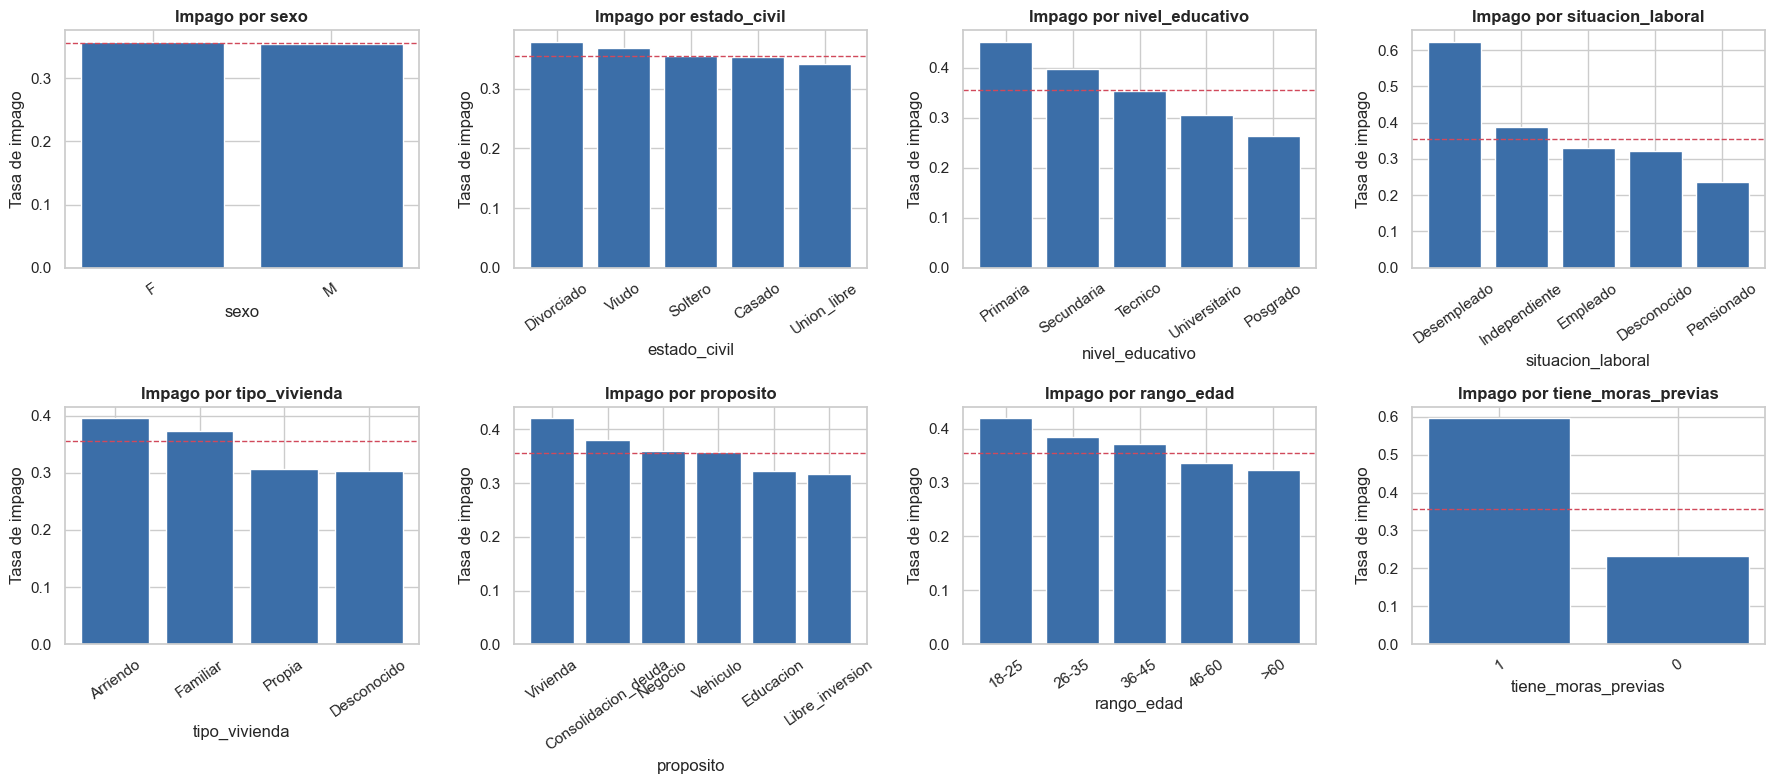

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), CAT):
    t = df.groupby(col)[TARGET].mean()
    if col == "nivel_educativo": t = t.reindex(ORDEN_EDU)
    elif col == "rango_edad": t = t.reindex(ORDEN_EDAD)
    else: t = t.sort_values(ascending=False)
    ax.bar(t.index.astype(str), t.values, color="#3b6ea8")
    ax.axhline(df[TARGET].mean(), ls="--", color="#d1495b", lw=1)
    ax.set_title(f"Impago por {col}"); ax.set_ylabel("Tasa de impago"); ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

**Lectura:** en el bivariado, las diferencias más grandes están en `tiene_moras_previas`, `situacion_laboral` (Desempleado), `nivel_educativo` (gradiente descendente) y `rango_edad` (los jóvenes incumplen más). `sexo` y `estado_civil` están cerca del promedio (línea roja).

### 1.3 Multivariado y segmentos

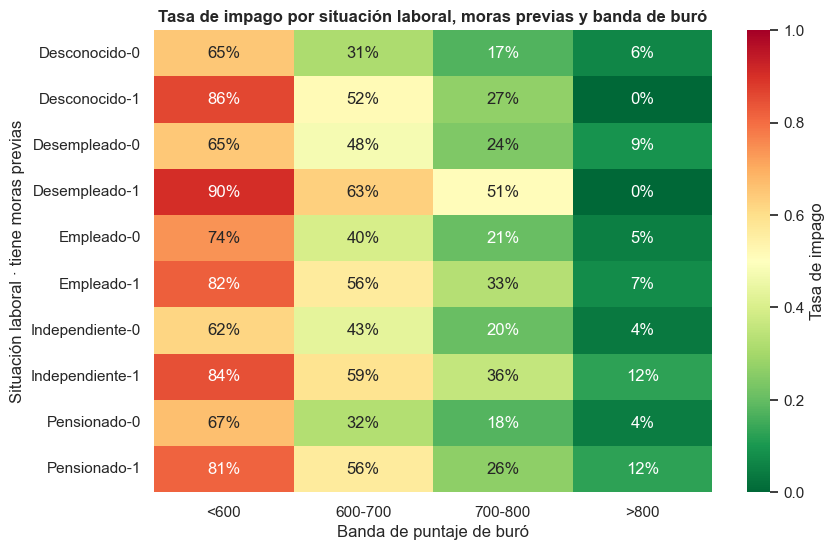

In [6]:
# Tasa de impago por segmentos combinados: situación laboral x moras previas x banda de buró
seg = (df.assign(banda_buro=pd.cut(df["puntaje_buro"], [0, 600, 700, 800, 1000], labels=["<600", "600-700", "700-800", ">800"]))
         .pivot_table(index=["situacion_laboral", "tiene_moras_previas"], columns="banda_buro",
                      values=TARGET, aggfunc="mean", observed=True))
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(seg, annot=True, fmt=".0%", cmap="RdYlGn_r", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Tasa de impago"})
ax.set_title("Tasa de impago por situación laboral, moras previas y banda de buró")
ax.set_xlabel("Banda de puntaje de buró"); ax.set_ylabel("Situación laboral · tiene moras previas"); plt.show()

**Lectura:** los efectos se **acumulan**: un empleado sin moras y con buró > 800 tiene un impago muy bajo, mientras que un desempleado con moras y buró < 600 alcanza ≈ 90 %. El riesgo es multivariado, lo que justifica modelos que combinen variables.

## 2. IA2.1 / IA2.2 · Manipulación con Pandas
### 2.1 `groupby` con varias agregaciones + `merge`

In [7]:
tasa_proposito = (df.groupby("proposito")
                    .agg(n=("default", "size"), tasa_impago_proposito=("default", "mean"),
                         monto_mediano=("monto_credito", "median"), plazo_medio=("plazo_meses", "mean"))
                    .reset_index())
tasa_laboral = df.groupby("situacion_laboral", as_index=False)["default"].mean().rename(columns={"default": "tasa_impago_laboral"})

# merge: enriquecer cada cliente con la tasa de su segmento (target encoding exploratorio)
df_seg = (df.merge(tasa_proposito[["proposito", "tasa_impago_proposito"]], on="proposito", how="left")
            .merge(tasa_laboral, on="situacion_laboral", how="left"))
display(tasa_proposito.round(3))
df_seg[["id_cliente", "proposito", "tasa_impago_proposito", "situacion_laboral", "tasa_impago_laboral", "default"]].head()

,proposito,n,tasa_impago_proposito,monto_mediano,plazo_medio
0,Consolidacion_deuda,1550,0.380,"8,857,000.000",32.071
1,Educacion,958,0.323,"10,630,500.000",31.353
2,Libre_inversion,2720,0.317,"7,158,000.000",32.411
3,Negocio,1364,0.361,"14,115,500.000",33.567
4,Vehiculo,1651,0.359,"18,598,000.000",33.256
5,Vivienda,1357,0.421,"55,057,000.000",31.968


,id_cliente,proposito,tasa_impago_proposito,situacion_laboral,tasa_impago_laboral,default
0,CLI_006413,Consolidacion_deuda,0.380,Pensionado,0.237,0
1,CLI_008728,Libre_inversion,0.317,Empleado,0.329,0
2,CLI_002268,Libre_inversion,0.317,Independiente,0.389,0
3,CLI_008456,Negocio,0.361,Empleado,0.329,1
4,CLI_008779,Libre_inversion,0.317,Independiente,0.389,1


### 2.2 `melt` y `pivot`

In [8]:
# melt: de formato ancho a largo (útil para graficar varias variables con facetas)
largo = df[["id_cliente", "default", "puntaje_buro", "uso_cupo_tarjetas", "relacion_deuda_ingreso"]].melt(
    id_vars=["id_cliente", "default"], var_name="variable", value_name="valor")
print("melt ->", largo.shape); display(largo.head())
# pivot: de largo a ancho (medias por variable y clase)
largo.groupby(["variable", "default"])["valor"].mean().reset_index().pivot(index="variable", columns="default", values="valor").round(3)

melt -> (28800, 4)


,id_cliente,default,variable,valor
0,CLI_006413,0,puntaje_buro,805.000
1,CLI_008728,0,puntaje_buro,738.000
2,CLI_002268,0,puntaje_buro,779.000
3,CLI_008456,1,puntaje_buro,639.000
4,CLI_008779,1,puntaje_buro,676.000


default,0,1
variable,,
puntaje_buro,754.857,625.243
relacion_deuda_ingreso,0.539,0.767
uso_cupo_tarjetas,0.361,0.624


### 2.3 `apply`, `map`, `cut` y `qcut`

In [9]:
ejemplo = df[["edad", "ingreso_mensual", "puntaje_buro", "nivel_educativo", "moras_ultimos_12m"]].copy()
# map: diccionario -> nivel educativo ordinal
ejemplo["edu_num"] = ejemplo["nivel_educativo"].map({n: i for i, n in enumerate(ORDEN_EDU)})
# apply por fila: regla de negocio de alerta temprana
ejemplo["alerta"] = ejemplo.apply(lambda r: "Alta" if (r["puntaje_buro"] < 600 and r["moras_ultimos_12m"] > 0) else "Normal", axis=1)
# cut: bandas fijas del buró; qcut: quintiles del ingreso
ejemplo["banda_buro"] = pd.cut(ejemplo["puntaje_buro"], bins=[0, 600, 700, 800, 1000], labels=["Malo", "Regular", "Bueno", "Excelente"])
ejemplo["quintil_ingreso"] = pd.qcut(ejemplo["ingreso_mensual"], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
display(ejemplo.head())
print(pd.crosstab(ejemplo["banda_buro"], df[TARGET], normalize="index").round(3))

,edad,ingreso_mensual,puntaje_buro,nivel_educativo,moras_ultimos_12m,edu_num,alerta,banda_buro,quintil_ingreso
0,23,"1,840,000.000",805,Tecnico,1,2,Normal,Excelente,Q2
1,79,"3,954,000.000",738,Secundaria,0,1,Normal,Bueno,Q5
2,63,"1,187,000.000",779,Primaria,0,0,Normal,Bueno,Q1
3,29,"1,181,000.000",639,Secundaria,2,1,Normal,Regular,Q1
4,27,"2,160,000.000",676,Posgrado,0,4,Normal,Regular,Q3


default        0     1
banda_buro            
Malo       0.192 0.808
Regular    0.528 0.472
Bueno      0.765 0.235
Excelente  0.951 0.049


### 2.4 Encadenamiento con `assign` y `pipe`

In [10]:
def filtrar_validos(d, col, minimo):
    return d[d[col] >= minimo]

def resumen_por(d, col):
    return d.groupby(col, observed=True).agg(clientes=("default", "size"), tasa_impago=("default", "mean"),
                                             cuota_ingreso_mediana=("ratio_cuota_ingreso", "median"))

(df.assign(log_ingreso=lambda d: np.log1p(d["ingreso_mensual"]),
           quintil_ingreso=lambda d: pd.qcut(d["log_ingreso"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]))
   .pipe(filtrar_validos, "plazo_meses", 6)
   .pipe(resumen_por, "quintil_ingreso")
   .round(3))

,clientes,tasa_impago,cuota_ingreso_mediana
quintil_ingreso,,,
Q1,1923,0.445,0.280
Q2,1918,0.342,0.274
Q3,1921,0.347,0.274
Q4,1918,0.324,0.278
Q5,1920,0.320,0.281


**Lectura:** el impago disminuye a medida que sube el quintil de ingreso y, a la vez, la carga cuota/ingreso mediana cae: los clientes de menor ingreso tienen menos holgura para pagar.

### 2.5 Equivalente en R con **dplyr**
El notebook está en Python; para cubrir la mención de dplyr, estas son las operaciones equivalentes en R:

```r
library(dplyr)
creditos <- readr::read_csv("db/processed/train.csv")

# filter: clientes con moras y buró bajo        (pandas: df.query("moras_ultimos_12m > 0 and puntaje_buro < 600"))
riesgosos <- creditos %>% filter(moras_ultimos_12m > 0, puntaje_buro < 600)

# select: columnas de interés                     (pandas: df[["edad", "ingreso_mensual", "default"]])
creditos %>% select(edad, ingreso_mensual, default)

# group_by %>% summarise: tasa de impago por situación laboral
#                                                 (pandas: df.groupby("situacion_laboral").agg(...))
creditos %>%
  group_by(situacion_laboral) %>%
  summarise(clientes = n(), tasa_impago = mean(default), ingreso_mediano = median(ingreso_mensual)) %>%
  arrange(desc(tasa_impago))
```

## 3. IA2.3 · Visualización con las tres librerías
### 3.1 Matplotlib: figura con subplots

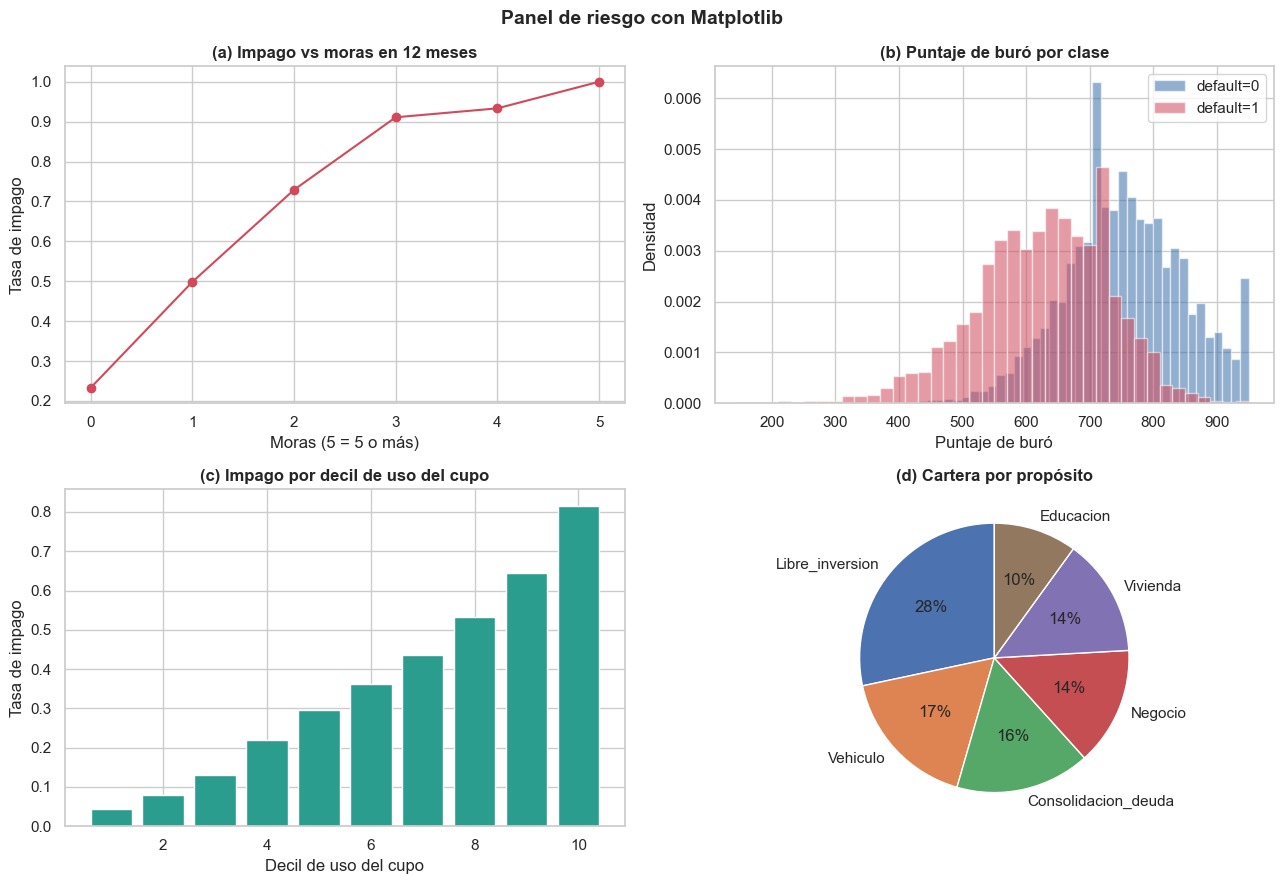

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
# (a) Tasa de impago por número de moras
t = df.groupby(df["moras_ultimos_12m"].clip(upper=5))[TARGET].mean()
axes[0, 0].plot(t.index, t.values, marker="o", color="#d1495b")
axes[0, 0].set_title("(a) Impago vs moras en 12 meses"); axes[0, 0].set_xlabel("Moras (5 = 5 o más)"); axes[0, 0].set_ylabel("Tasa de impago")
# (b) Distribución del buró por clase
for k, color in [(0, "#3b6ea8"), (1, "#d1495b")]:
    axes[0, 1].hist(df.loc[df[TARGET] == k, "puntaje_buro"], bins=40, alpha=0.55, color=color, density=True, label=f"default={k}")
axes[0, 1].set_title("(b) Puntaje de buró por clase"); axes[0, 1].set_xlabel("Puntaje de buró"); axes[0, 1].set_ylabel("Densidad"); axes[0, 1].legend()
# (c) Impago por decil de uso del cupo
dec = df.groupby(pd.qcut(df["uso_cupo_tarjetas"], 10, duplicates="drop"), observed=True)[TARGET].mean()
axes[1, 0].bar(range(1, len(dec) + 1), dec.values, color="#2a9d8f")
axes[1, 0].set_title("(c) Impago por decil de uso del cupo"); axes[1, 0].set_xlabel("Decil de uso del cupo"); axes[1, 0].set_ylabel("Tasa de impago")
# (d) Composición de la cartera por propósito
cnt = df["proposito"].value_counts()
axes[1, 1].pie(cnt.values, labels=cnt.index, autopct="%1.0f%%", startangle=90, colors=sns.color_palette("deep", len(cnt)))
axes[1, 1].set_title("(d) Cartera por propósito")
plt.suptitle("Panel de riesgo con Matplotlib", fontsize=14, fontweight="bold"); plt.tight_layout(); plt.show()

**Interpretación:** (a) el impago crece casi linealmente con las moras hasta saturarse; (b) las distribuciones de buró de pagadores e impagos están claramente desplazadas; (c) el impago sube de forma monótona con el uso del cupo; (d) libre inversión es el propósito más frecuente (~28 %).

### 3.2 Seaborn: `heatmap` de correlaciones, `pairplot` y `violinplot`

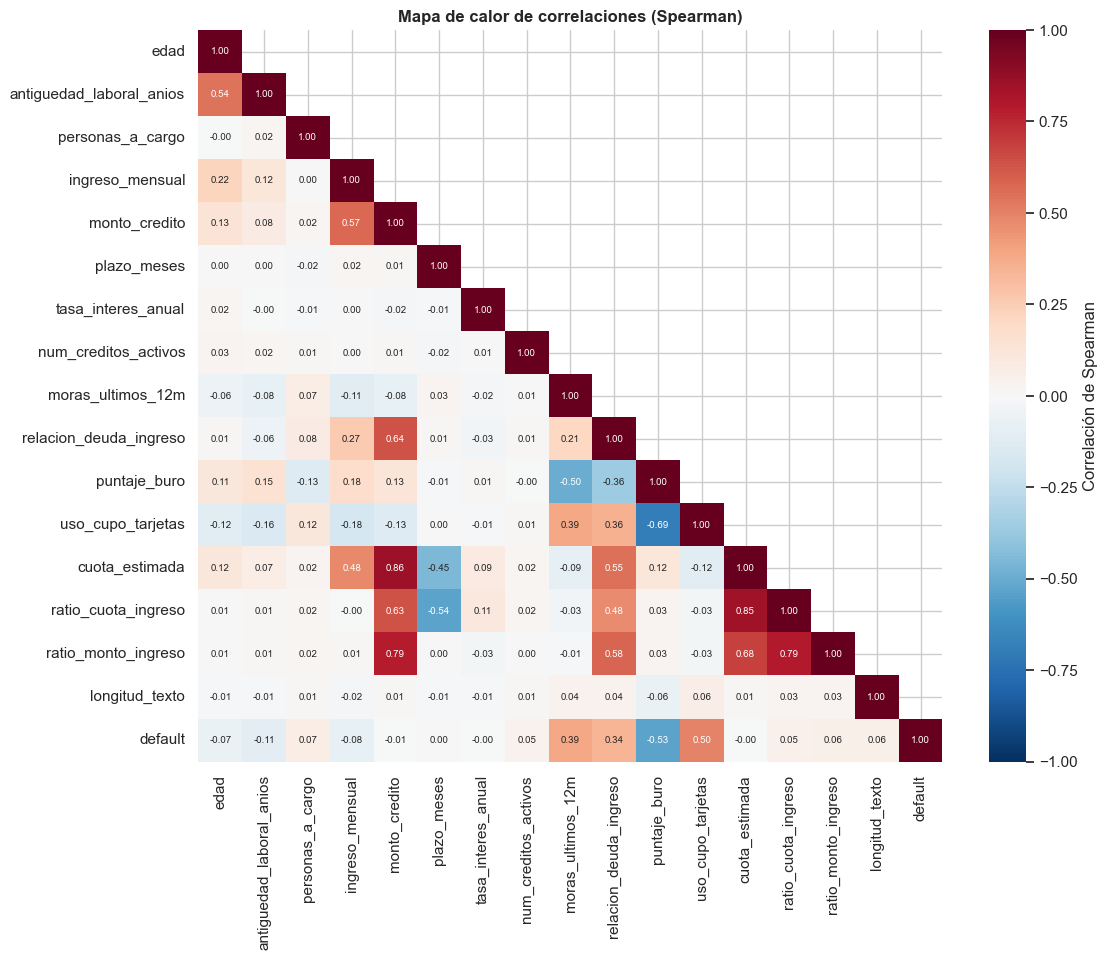

In [12]:
corr_s = df[NUM + [TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 9.5))
mask = np.triu(np.ones_like(corr_s, dtype=bool), k=1)
sns.heatmap(corr_s, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "Correlación de Spearman"})
ax.set_title("Mapa de calor de correlaciones (Spearman)"); plt.show()

**Interpretación:** con el objetivo destacan `puntaje_buro` (negativa fuerte), `uso_cupo_tarjetas`, `moras_ultimos_12m` y `relacion_deuda_ingreso` (positivas). Entre predictores, `monto_credito`, `cuota_estimada` y los ratios están muy correlacionados entre sí (redundancia), igual que `edad` con `antiguedad_laboral_anios`.

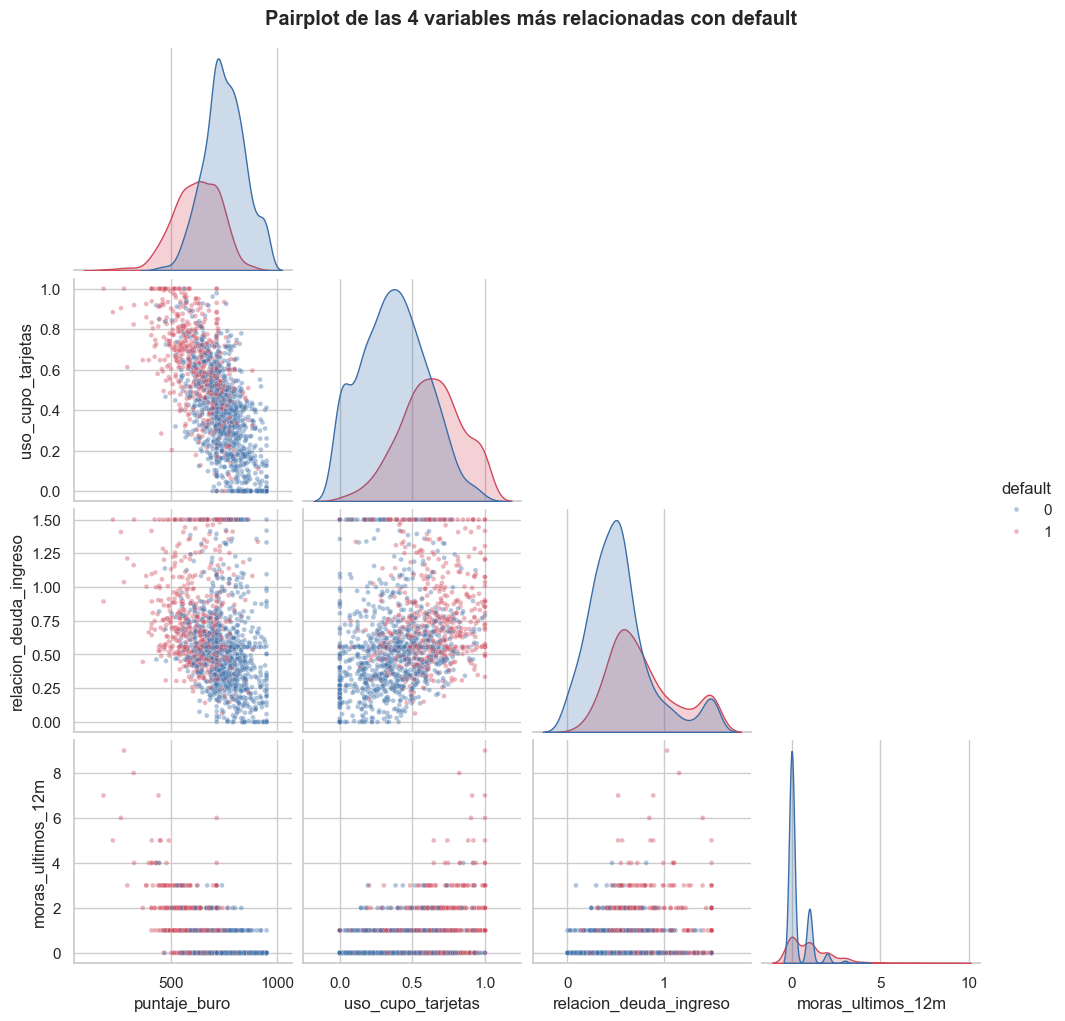

In [13]:
vars_pair = ["puntaje_buro", "uso_cupo_tarjetas", "relacion_deuda_ingreso", "moras_ultimos_12m", TARGET]
g = sns.pairplot(df[vars_pair].sample(1500, random_state=RANDOM_STATE), hue=TARGET, corner=True,
                 palette={0: "#3b6ea8", 1: "#d1495b"}, plot_kws={"alpha": 0.4, "s": 12}, diag_kind="kde")
g.figure.suptitle("Pairplot de las 4 variables más relacionadas con default", y=1.02, fontweight="bold"); plt.show()

**Interpretación:** ninguna variable separa sola las clases, pero en los planos buró-uso del cupo y buró-DTI los impagos ocupan regiones distintas: la combinación de variables es la que discrimina.

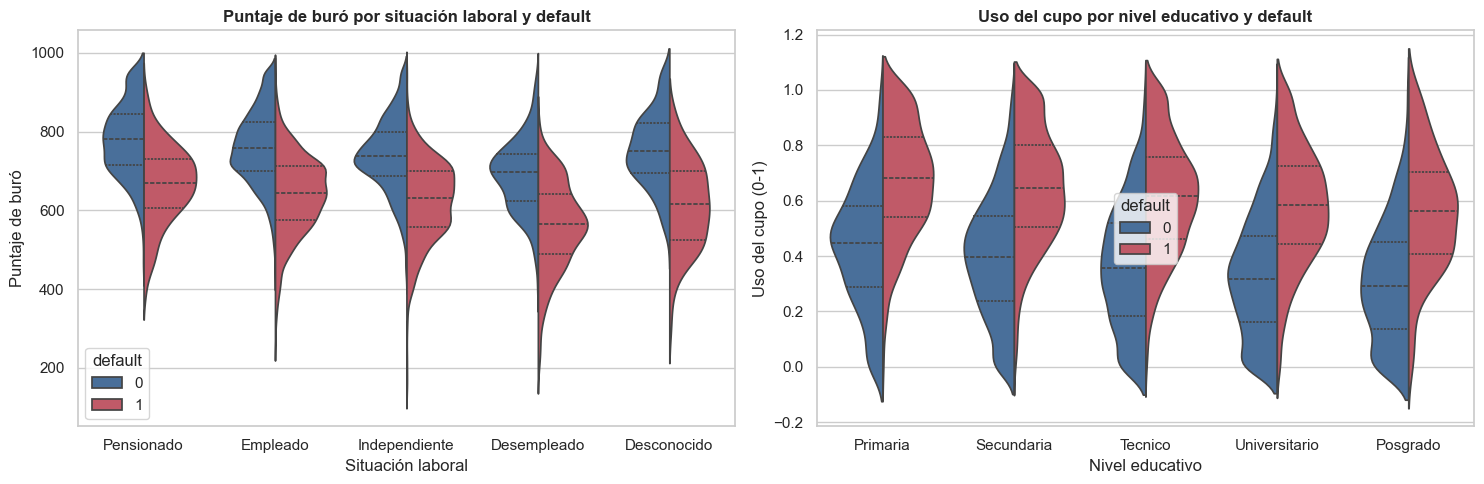

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.violinplot(data=df, x="situacion_laboral", y="puntaje_buro", hue=TARGET, split=True, inner="quart",
               palette={0: "#3b6ea8", 1: "#d1495b"}, ax=axes[0])
axes[0].set_title("Puntaje de buró por situación laboral y default"); axes[0].set_xlabel("Situación laboral"); axes[0].set_ylabel("Puntaje de buró")
sns.violinplot(data=df, x="nivel_educativo", y="uso_cupo_tarjetas", hue=TARGET, split=True, inner="quart", order=ORDEN_EDU,
               palette={0: "#3b6ea8", 1: "#d1495b"}, ax=axes[1])
axes[1].set_title("Uso del cupo por nivel educativo y default"); axes[1].set_xlabel("Nivel educativo"); axes[1].set_ylabel("Uso del cupo (0-1)")
plt.tight_layout(); plt.show()

**Interpretación:** en todas las situaciones laborales y niveles educativos, los impagos (mitad roja) tienen un buró más bajo y un uso del cupo más alto: el efecto de estas variables es **consistente entre segmentos**, no depende de un grupo concreto.

### 3.3 ggplot2 con **plotnine**
`plotnine` implementa la gramática de gráficos de ggplot2 en Python (`ggplot(aes(...)) + geom_* + facet_wrap`).

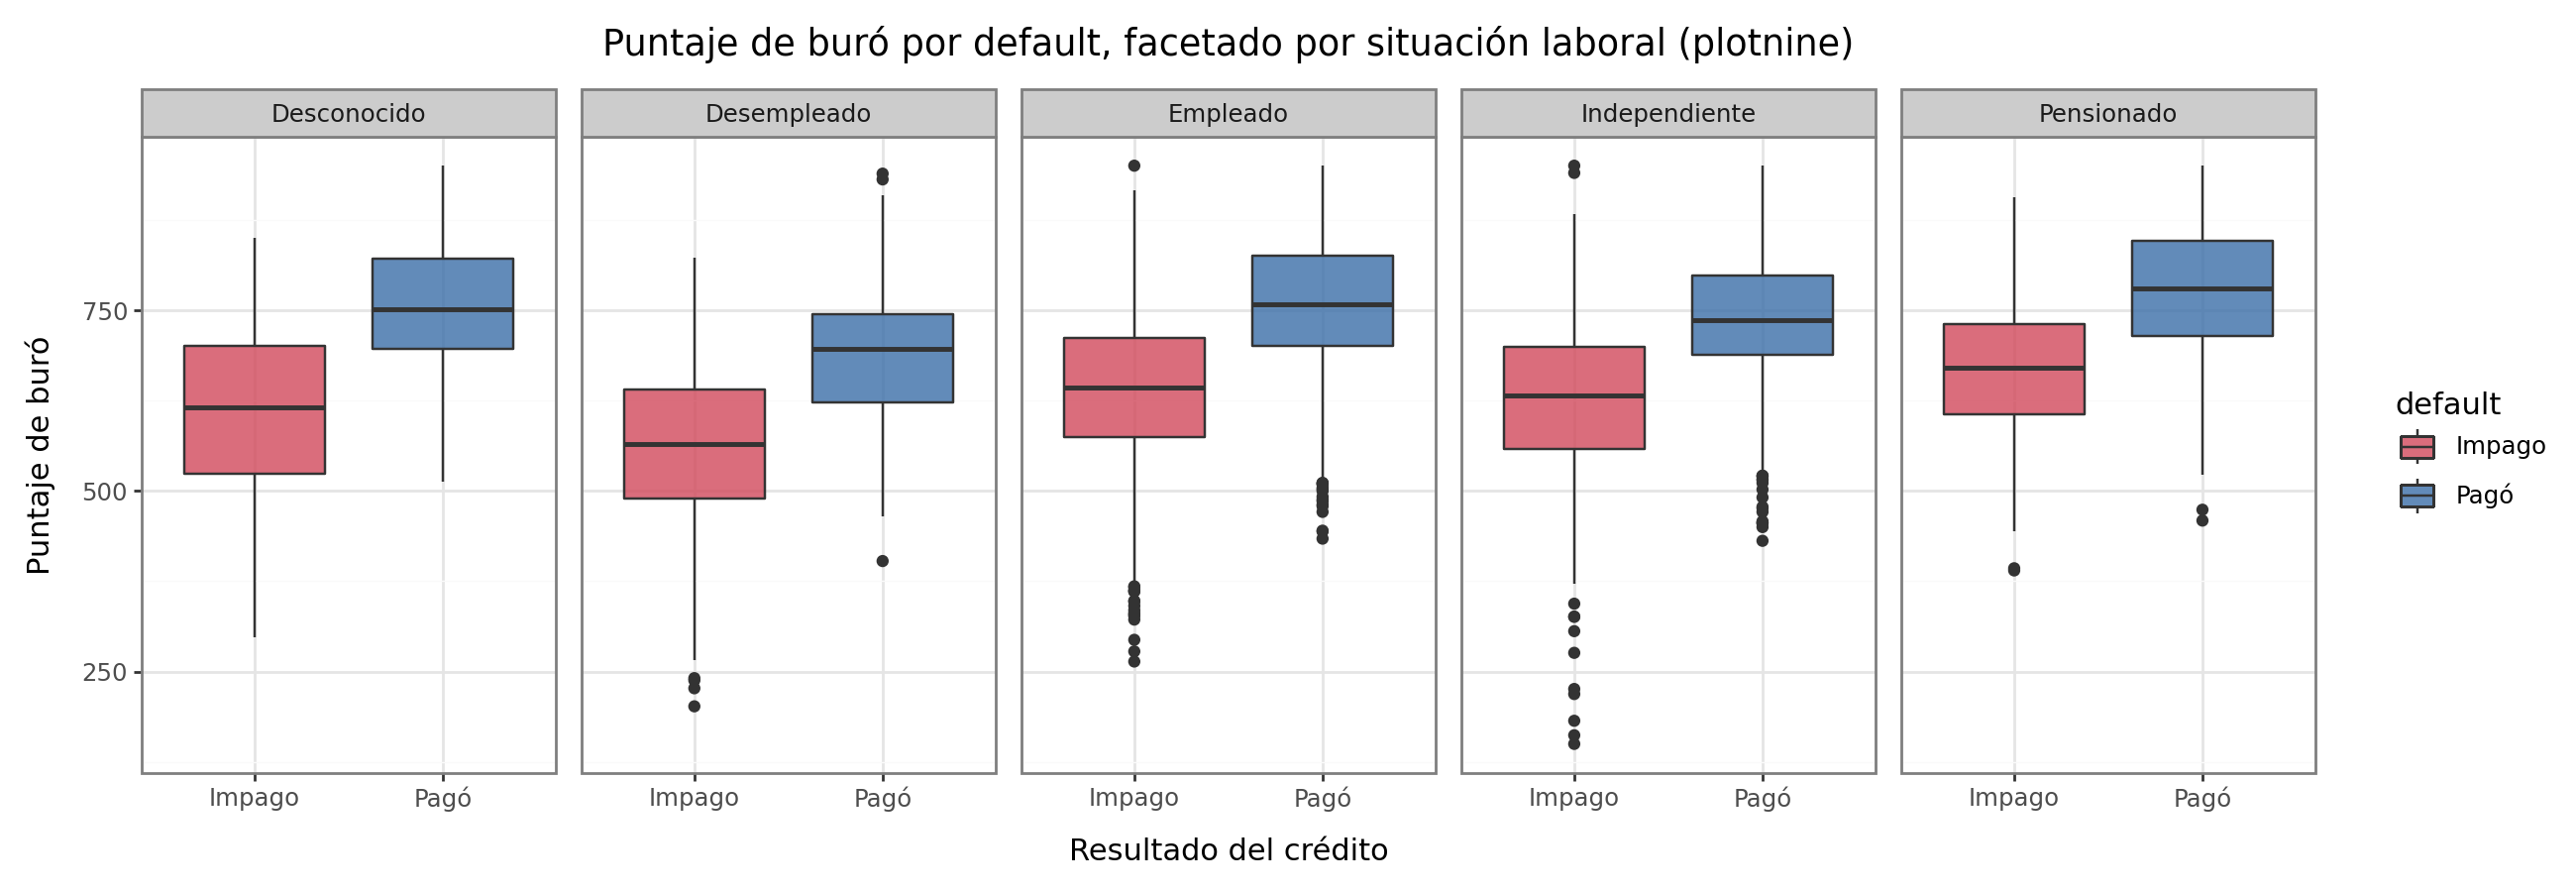

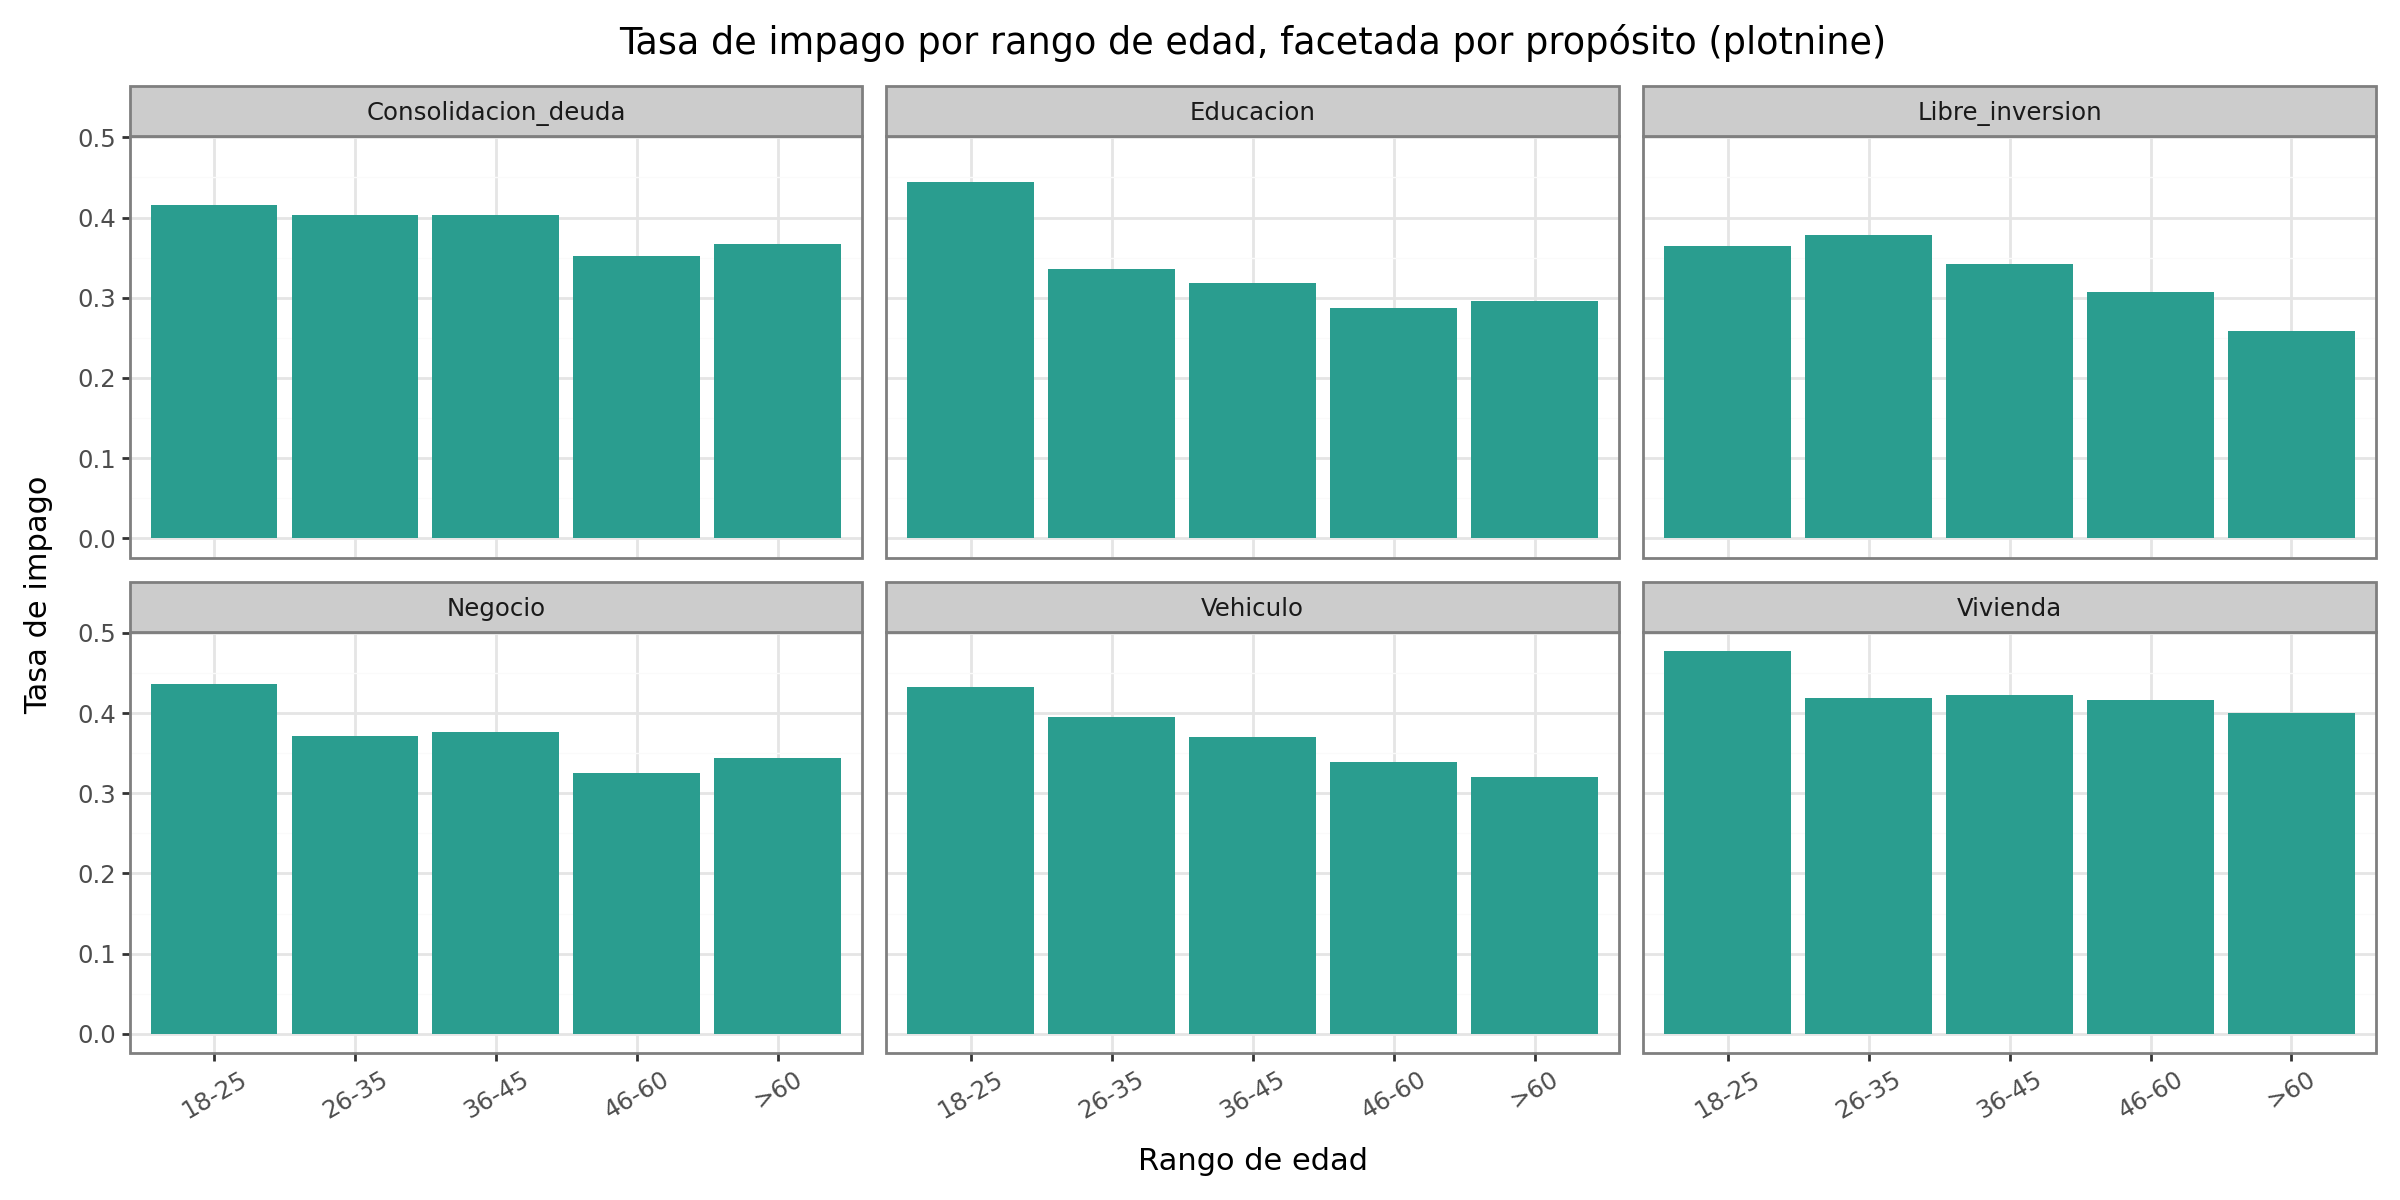

In [15]:
try:
    from plotnine import (ggplot, aes, geom_boxplot, geom_col, facet_wrap, labs, theme_bw, theme,
                          element_text, scale_fill_manual, coord_flip)
    datos_gg = df.assign(default_txt=df[TARGET].map({0: "Pagó", 1: "Impago"}))
    p1 = (ggplot(datos_gg, aes(x="default_txt", y="puntaje_buro", fill="default_txt"))
          + geom_boxplot(alpha=0.8)
          + facet_wrap("~situacion_laboral", ncol=5)
          + scale_fill_manual(values=["#d1495b", "#3b6ea8"])
          + labs(title="Puntaje de buró por default, facetado por situación laboral (plotnine)",
                 x="Resultado del crédito", y="Puntaje de buró", fill="default")
          + theme_bw() + theme(figure_size=(13, 4.5)))
    display(p1)
    tasa_gg = (df.groupby(["proposito", "rango_edad"])[TARGET].mean().reset_index(name="tasa_impago"))
    p2 = (ggplot(tasa_gg, aes(x="rango_edad", y="tasa_impago"))
          + geom_col(fill="#2a9d8f")
          + facet_wrap("~proposito", ncol=3)
          + labs(title="Tasa de impago por rango de edad, facetada por propósito (plotnine)", x="Rango de edad", y="Tasa de impago")
          + theme_bw() + theme(figure_size=(12, 6), axis_text_x=element_text(rotation=30)))
    display(p2)
except ImportError as e:
    print("plotnine no está instalado (pip install plotnine). Celda omitida:", e)

**Interpretación:** con la gramática de ggplot2 las facetas muestran que la brecha de buró entre pagadores e impagos se repite en cada situación laboral, y que en casi todos los propósitos el impago es mayor en el rango 18-25 años.

## 4. IA2.E1 · Patrones y correlaciones
### 4.1 Pearson vs Spearman con el objetivo

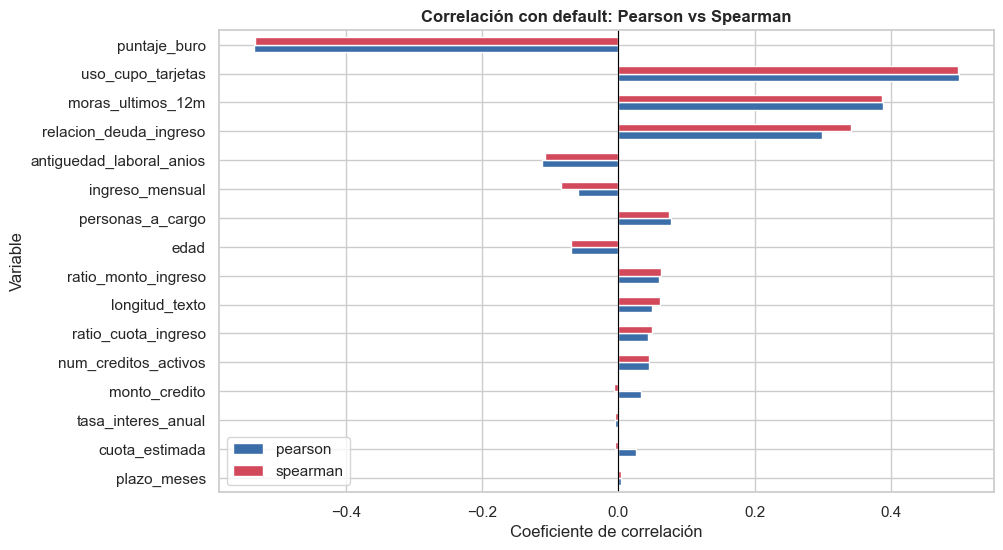

,pearson,spearman,diferencia
puntaje_buro,-0.534,-0.533,0.001
uso_cupo_tarjetas,0.499,0.499,0.001
moras_ultimos_12m,0.388,0.387,0.001
relacion_deuda_ingreso,0.299,0.341,0.043
antiguedad_laboral_anios,-0.112,-0.108,0.004
ingreso_mensual,-0.059,-0.084,0.025
personas_a_cargo,0.077,0.075,0.003
edad,-0.069,-0.069,0.000
ratio_monto_ingreso,0.060,0.062,0.002
longitud_texto,0.049,0.061,0.012


In [16]:
corr_obj = pd.DataFrame({"pearson": df[NUM].corrwith(df[TARGET], method="pearson"),
                         "spearman": df[NUM].corrwith(df[TARGET], method="spearman")})
corr_obj["diferencia"] = (corr_obj["spearman"] - corr_obj["pearson"]).abs()
corr_obj = corr_obj.reindex(corr_obj["spearman"].abs().sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(10, 6))
corr_obj[["pearson", "spearman"]].iloc[::-1].plot.barh(ax=ax, color=["#3b6ea8", "#d1495b"])
ax.axvline(0, color="black", lw=0.8); ax.set_title("Correlación con default: Pearson vs Spearman")
ax.set_xlabel("Coeficiente de correlación"); ax.set_ylabel("Variable"); plt.show()
corr_obj.round(3)

**Lectura:** en las variables acotadas (buró, uso del cupo, moras) Pearson y Spearman coinciden. En las monetarias y en la DTI difieren: `ingreso_mensual` (−0.06 Pearson vs −0.08 Spearman), `relacion_deuda_ingreso` (0.30 vs 0.34) y `monto_credito` / `cuota_estimada`, cuyo Pearson positivo lo producen unos pocos valores extremos (Spearman ≈ 0). Pearson se distorsiona con los atípicos y las relaciones son monótonas pero no lineales: se confirma la necesidad de tratar los atípicos o usar escalas logarítmicas.

### 4.2 V de Cramér: categóricas vs `default`

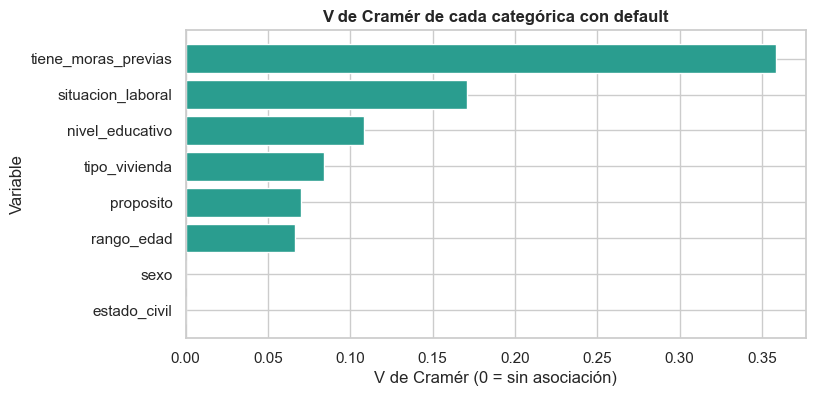

,v_cramer,p_valor_chi2
estado_civil,0.000,0.439
nivel_educativo,0.108,0.000
proposito,0.070,0.000
rango_edad,0.066,0.000
sexo,0.000,0.674
situacion_laboral,0.171,0.000
tiene_moras_previas,0.359,0.000
tipo_vivienda,0.084,0.000


In [17]:
def cramers_v(x, y):
    """V de Cramér con corrección de sesgo (Bergsma, 2013)."""
    tabla = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum(); r, k = tabla.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-12, min(k_c - 1, r_c - 1)))

v_cramer = pd.Series({c: cramers_v(df[c], df[TARGET]) for c in CAT}).sort_values(ascending=False)
p_chi2 = pd.Series({c: stats.chi2_contingency(pd.crosstab(df[c], df[TARGET]))[1] for c in CAT})
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(v_cramer.index[::-1], v_cramer.values[::-1], color="#2a9d8f")
ax.set_title("V de Cramér de cada categórica con default"); ax.set_xlabel("V de Cramér (0 = sin asociación)"); ax.set_ylabel("Variable")
plt.show()
pd.DataFrame({"v_cramer": v_cramer, "p_valor_chi2": p_chi2}).round(4)

### 4.3 Cinco hallazgos principales

1. **El historial crediticio domina el riesgo.** `puntaje_buro` (Spearman ≈ −0.53) y `moras_ultimos_12m` (≈ +0.39) son las variables más asociadas al impago; tener al menos una mora previa más que duplica la tasa (≈ 23 % → ≈ 60 %).
2. **El uso del cupo y el endeudamiento anticipan el impago.** `uso_cupo_tarjetas` (≈ +0.50) y `relacion_deuda_ingreso` (≈ +0.34) crecen de forma monótona con la tasa de impago: los clientes "apretados" financieramente incumplen más.
3. **La estabilidad laboral protege.** Los desempleados (≈ 62 %) e independientes (≈ 39 %) incumplen mucho más que empleados y pensionados; más antigüedad laboral y más educación se asocian a menos impago (`situacion_laboral` tiene una de las V de Cramér más altas, solo por detrás del historial de moras).
4. **Monto, plazo y tasa por sí solos casi no discriminan** (correlación ≈ 0); su información aparece al combinarlos con el ingreso (ratios) y, sobre todo, con el comportamiento de pago.
5. **Las variables sensibles aportan poco.** `sexo` y `estado_civil` tienen V de Cramér cercana a 0 (sin asociación relevante), lo que respalda excluir `sexo`; la **edad** sí tiene un efecto (los jóvenes incumplen más), por lo que debe auditarse en el paso 8 para que no genere un *disparate impact* < 0.8.

## 5. IA2.5 · Atípicos
### 5.1 Detección con IQR y z-score

In [18]:
CONT = ["edad", "antiguedad_laboral_anios", "ingreso_mensual", "monto_credito", "tasa_interes_anual",
        "relacion_deuda_ingreso", "puntaje_buro", "uso_cupo_tarjetas", "cuota_estimada",
        "ratio_cuota_ingreso", "ratio_monto_ingreso", "num_creditos_activos", "moras_ultimos_12m"]

def atipicos_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def atipicos_z(s, umbral=3):
    return np.abs(stats.zscore(s)) > umbral

det = pd.DataFrame({"atipicos_IQR": {c: atipicos_iqr(df[c]).sum() for c in CONT},
                    "atipicos_z>3": {c: atipicos_z(df[c]).sum() for c in CONT}})
det["pct_IQR"] = (det["atipicos_IQR"] / len(df) * 100).round(2)
det["pct_z"] = (det["atipicos_z>3"] / len(df) * 100).round(2)
det.sort_values("atipicos_IQR", ascending=False)

,atipicos_IQR,atipicos_z>3,pct_IQR,pct_z
ratio_monto_ingreso,1126,168,11.730,1.750
ratio_cuota_ingreso,982,200,10.230,2.080
cuota_estimada,966,156,10.060,1.620
monto_credito,939,165,9.780,1.720
num_creditos_activos,734,60,7.650,0.620
relacion_deuda_ingreso,700,0,7.290,0.000
ingreso_mensual,446,69,4.650,0.720
antiguedad_laboral_anios,441,112,4.590,1.170
moras_ultimos_12m,383,136,3.990,1.420
puntaje_buro,119,40,1.240,0.420


**Lectura:** IQR marca más atípicos en las variables asimétricas (ingreso, monto, cuota y ratios) porque su cola derecha es larga por naturaleza; el z-score (|z| > 3) es más conservador. En `moras_ultimos_12m` y `num_creditos_activos` los "atípicos" son valores altos legítimos (clientes con muchas moras), no errores.

### 5.2 Tratamiento: *capping* en p1-p99 (winsorizing)
**¿Por qué no eliminar filas?** (1) Un cliente con un ingreso mal digitado sigue teniendo información válida en las demás 20 columnas; (2) eliminar filas sesgaría la muestra (los atípicos no se distribuyen igual entre clases) y reduciría los datos; (3) en producción la API recibirá valores extremos y el modelo debe saber tratarlos, no descartarlos. El *capping* en p1-p99 conserva todas las filas y limita la influencia de los extremos. Los límites se calculan **en train** y se guardan para aplicarlos igual a test y a la API.

In [19]:
A_CAPEAR = ["ingreso_mensual", "monto_credito", "cuota_estimada", "ratio_cuota_ingreso", "ratio_monto_ingreso",
            "antiguedad_laboral_anios", "relacion_deuda_ingreso"]
LIMITES = {c: [float(df[c].quantile(0.01)), float(df[c].quantile(0.99))] for c in A_CAPEAR}
df_cap = df.copy()
for c, (lo, hi) in LIMITES.items():
    df_cap[c] = df_cap[c].clip(lo, hi)

antes_despues = pd.DataFrame({
    "max_antes": df[A_CAPEAR].max(), "max_despues": df_cap[A_CAPEAR].max(),
    "asimetria_antes": df[A_CAPEAR].skew(), "asimetria_despues": df_cap[A_CAPEAR].skew(),
    "filas_afectadas": [(df[c] != df_cap[c]).sum() for c in A_CAPEAR]})
antes_despues.round(2)

,max_antes,max_despues,asimetria_antes,asimetria_despues,filas_afectadas
ingreso_mensual,"64,540,000.000","7,816,150.000",10.810,1.440,191
monto_credito,"1,033,300,000.000","144,522,390.000",9.540,2.800,191
cuota_estimada,"78,233,341.990","11,020,996.400",9.710,3.380,192
ratio_cuota_ingreso,13.200,3.570,5.370,2.960,192
ratio_monto_ingreso,194.230,37.750,4.810,2.160,192
antiguedad_laboral_anios,62.000,52.300,1.320,1.270,95
relacion_deuda_ingreso,1.500,1.500,0.880,0.880,0


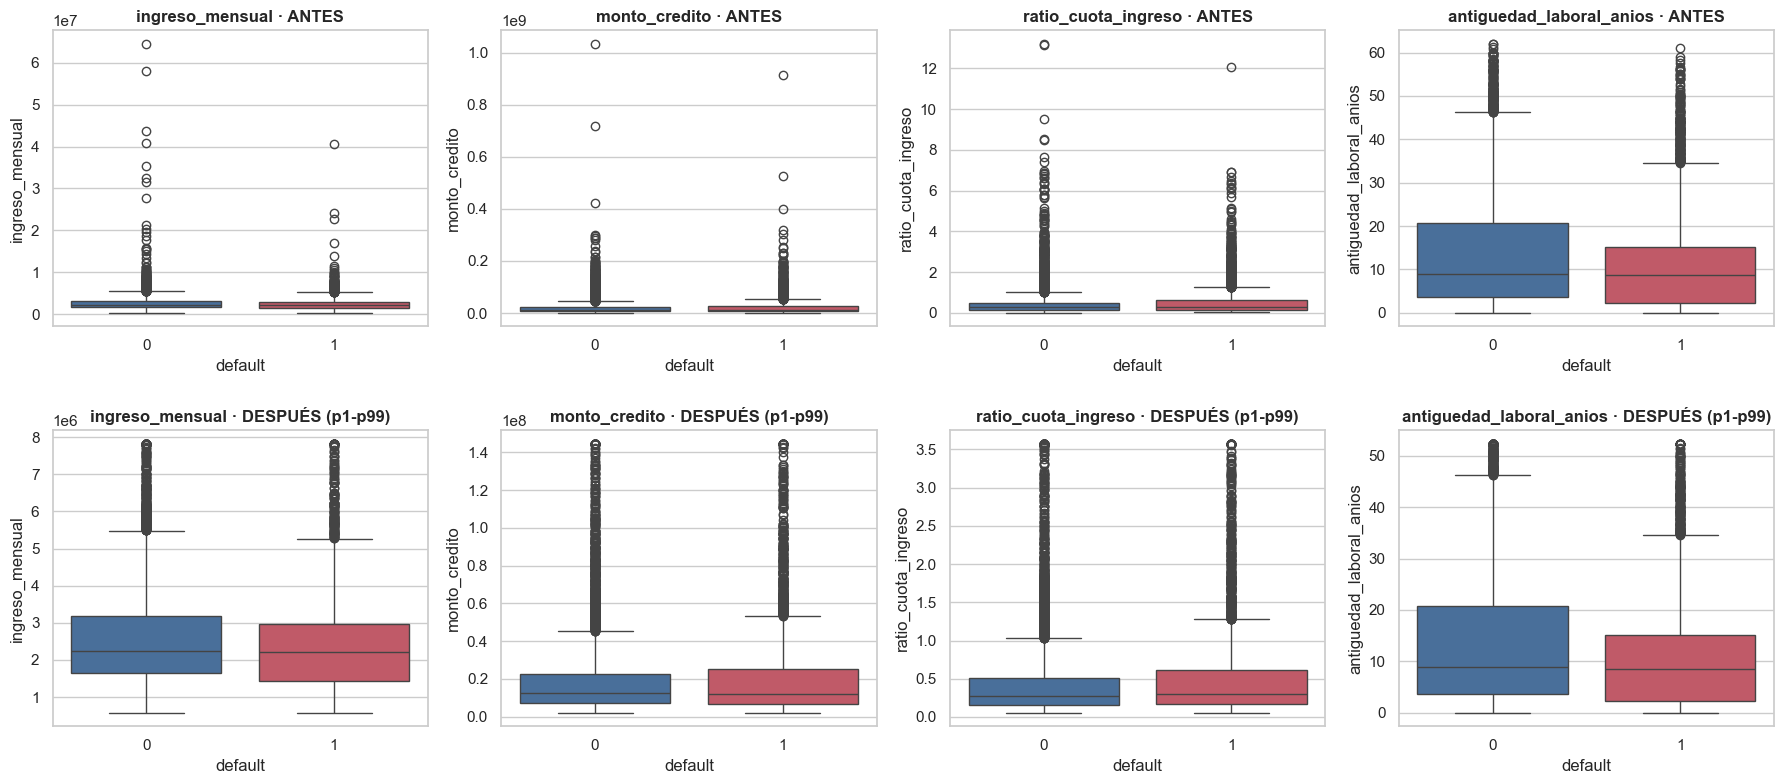

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, c in enumerate(["ingreso_mensual", "monto_credito", "ratio_cuota_ingreso", "antiguedad_laboral_anios"]):
    sns.boxplot(x=df[TARGET], y=df[c], ax=axes[0, i], palette=["#3b6ea8", "#d1495b"])
    axes[0, i].set_title(f"{c} · ANTES"); axes[0, i].set_xlabel("default"); axes[0, i].set_ylabel(c)
    sns.boxplot(x=df_cap[TARGET], y=df_cap[c], ax=axes[1, i], palette=["#3b6ea8", "#d1495b"])
    axes[1, i].set_title(f"{c} · DESPUÉS (p1-p99)"); axes[1, i].set_xlabel("default"); axes[1, i].set_ylabel(c)
plt.tight_layout(); plt.show()

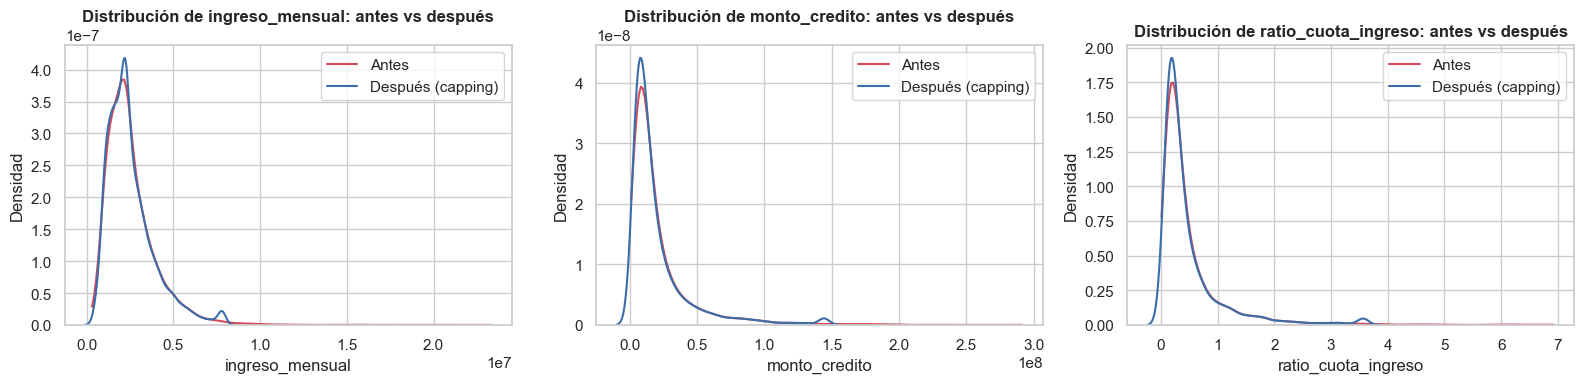

,pearson_antes,pearson_despues
ingreso_mensual,-0.059,-0.071
monto_credito,0.034,0.038
cuota_estimada,0.027,0.033
ratio_cuota_ingreso,0.044,0.056
ratio_monto_ingreso,0.060,0.069
antiguedad_laboral_anios,-0.112,-0.112
relacion_deuda_ingreso,0.299,0.299


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["ingreso_mensual", "monto_credito", "ratio_cuota_ingreso"]):
    sns.kdeplot(df[c], ax=ax, label="Antes", color="#d1495b", clip=(df[c].min(), df[c].quantile(0.999)))
    sns.kdeplot(df_cap[c], ax=ax, label="Después (capping)", color="#3b6ea8")
    ax.set_title(f"Distribución de {c}: antes vs después"); ax.set_xlabel(c); ax.set_ylabel("Densidad"); ax.legend()
plt.tight_layout(); plt.show()
corr_cmp = pd.DataFrame({"pearson_antes": df[A_CAPEAR].corrwith(df[TARGET]), "pearson_despues": df_cap[A_CAPEAR].corrwith(df_cap[TARGET])})
corr_cmp.round(3)

**Interpretación:** tras el *capping* desaparecen los bigotes extremos y la asimetría cae drásticamente (ingreso: de ≈ 10.8 a ≈ 1.4). La correlación de Pearson del ingreso y de los ratios con `default` se **fortalece** (ingreso: −0.059 → −0.071, acercándose al −0.084 de Spearman): la relación real ya no queda oculta por unos pocos errores de digitación. Solo ~2 % de las filas (≈ 190) se modifican por variable y **no se pierde ninguna**.

## 6. IA2.4 · Normalización, estandarización y PCA (sobre datos sin atípicos)

In [22]:
X_num = df_cap[NUM]
X_std = pd.DataFrame(StandardScaler().fit_transform(X_num), columns=NUM)
X_mm = pd.DataFrame(MinMaxScaler().fit_transform(X_num), columns=NUM)
pd.concat({"Estandarizado (media, std)": X_std.agg(["mean", "std"]).T,
           "Normalizado (min, max)": X_mm.agg(["min", "max"]).T}, axis=1).round(3).head(8)

Estandarizado (media, std)       Normalizado (min, max)      
                                               mean   std                    min   max
edad                                         -0.000 1.000                  0.000 1.000
antiguedad_laboral_anios                     -0.000 1.000                  0.000 1.000
personas_a_cargo                              0.000 1.000                  0.000 1.000
ingreso_mensual                              -0.000 1.000                  0.000 1.000
monto_credito                                -0.000 1.000                  0.000 1.000
plazo_meses                                  -0.000 1.000                  0.000 1.000
tasa_interes_anual                           -0.000 1.000                  0.000 1.000
num_creditos_activos                         -0.000 1.000                  0.000 1.000

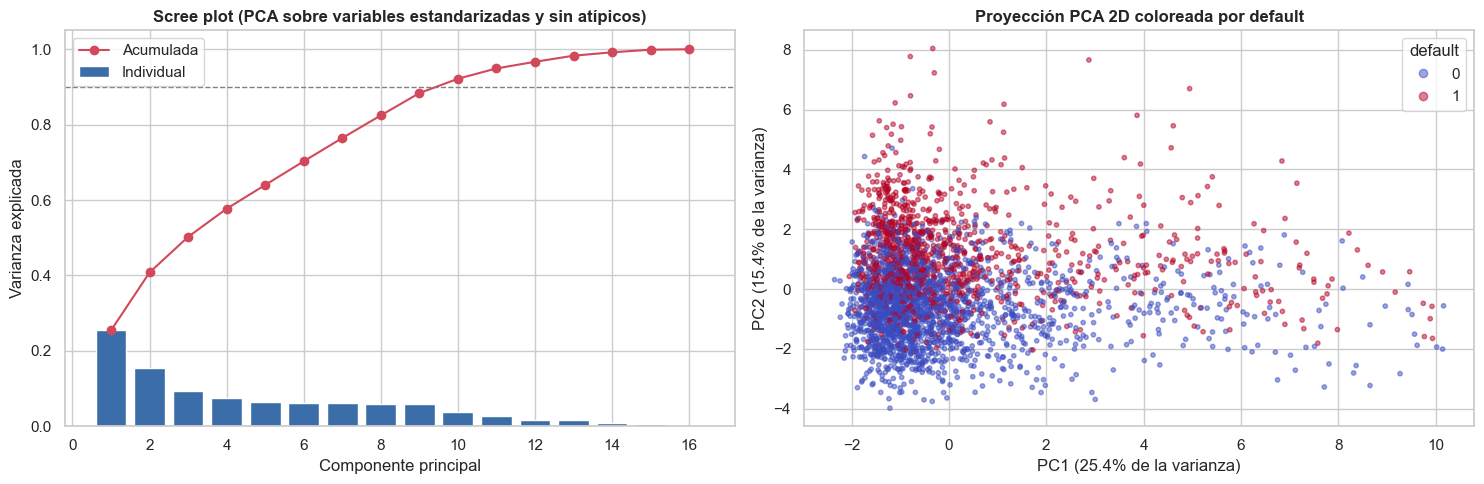

PC1+PC2 explican 40.8%; se necesitan 10 de 16 componentes para el 90 %


In [23]:
pca = PCA(random_state=RANDOM_STATE).fit(X_std)
var = pca.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(range(1, len(var) + 1), var, color="#3b6ea8", label="Individual")
axes[0].plot(range(1, len(var) + 1), np.cumsum(var), marker="o", color="#d1495b", label="Acumulada")
axes[0].axhline(0.9, ls="--", color="gray", lw=1)
axes[0].set_title("Scree plot (PCA sobre variables estandarizadas y sin atípicos)")
axes[0].set_xlabel("Componente principal"); axes[0].set_ylabel("Varianza explicada"); axes[0].legend()

Z = pca.transform(X_std)[:, :2]
idx = np.random.RandomState(RANDOM_STATE).choice(len(Z), 3000, replace=False)
sc = axes[1].scatter(Z[idx, 0], Z[idx, 1], c=df_cap[TARGET].values[idx], cmap="coolwarm", alpha=0.5, s=10)
axes[1].set_title("Proyección PCA 2D coloreada por default")
axes[1].set_xlabel(f"PC1 ({var[0]:.1%} de la varianza)"); axes[1].set_ylabel(f"PC2 ({var[1]:.1%} de la varianza)")
axes[1].legend(*sc.legend_elements(), title="default")
plt.tight_layout(); plt.show()
print(f"PC1+PC2 explican {var[:2].sum():.1%}; se necesitan {int(np.argmax(np.cumsum(var) >= 0.9) + 1)} de {len(var)} componentes para el 90 %")

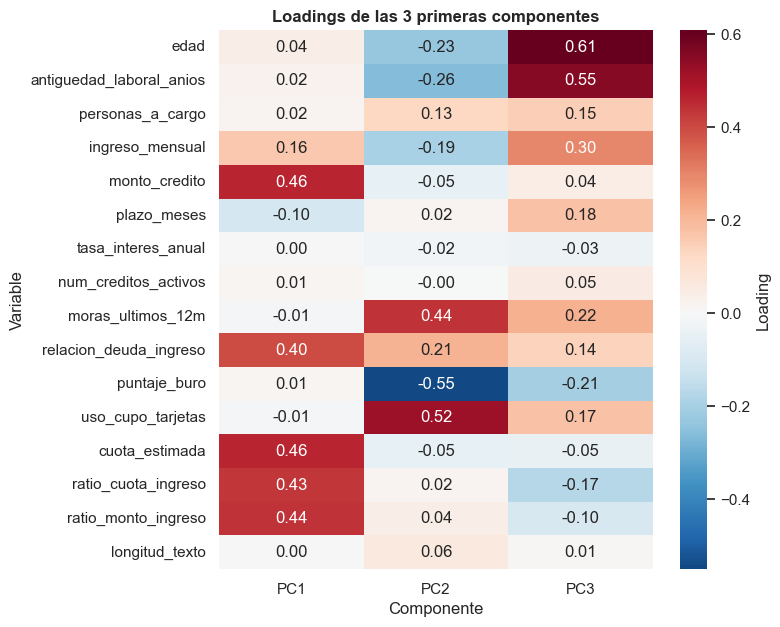

In [24]:
loadings = pd.DataFrame(pca.components_[:3].T, index=NUM, columns=["PC1", "PC2", "PC3"])
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "Loading"})
ax.set_title("Loadings de las 3 primeras componentes"); ax.set_xlabel("Componente"); ax.set_ylabel("Variable"); plt.show()

**Interpretación:** la varianza está repartida (PC1 + PC2 ≈ 41 %; se necesitan 10 de 16 componentes para el 90 %). **PC1** agrupa monto, cuota, ratios y DTI (el "tamaño/carga del crédito"); **PC2** es el eje de **comportamiento crediticio** (buró con signo negativo, uso del cupo y moras con signo positivo); **PC3** recoge la **madurez** del cliente (edad y antigüedad laboral). En la proyección 2D las clases se separan sobre todo a lo largo de **PC2** y se solapan en PC1: la componente de mayor varianza (tamaño del crédito) no es la más predictiva, lo que confirma que PCA no es una buena forma de seleccionar variables para este problema y que es mejor usar las variables originales (más explicables).

## 7. IA1.E2 / IA2.E2 · Variables relevantes y optimización
Ranking final combinando correlación de Spearman (numéricas), información mutua (todas) y V de Cramér (categóricas), calculados sobre train con atípicos tratados.

In [25]:
X_mi = df_cap[NUM].copy()
for c in CAT:
    X_mi[c] = df_cap[c].astype("category").cat.codes
mi = pd.Series(mutual_info_classif(X_mi, df_cap[TARGET], discrete_features=[c in CAT for c in X_mi.columns],
                                   random_state=RANDOM_STATE), index=X_mi.columns)
ranking = pd.DataFrame({
    "tipo": ["numérica" if c in NUM else "categórica" for c in X_mi.columns],
    "abs_spearman": [abs(df_cap[c].corr(df_cap[TARGET], method="spearman")) if c in NUM else np.nan for c in X_mi.columns],
    "v_cramer": [v_cramer.get(c, np.nan) for c in X_mi.columns],
    "info_mutua": mi.values}, index=X_mi.columns)
ranking["asociacion"] = ranking["abs_spearman"].fillna(ranking["v_cramer"])
ranking["rank"] = (ranking["asociacion"].rank(ascending=False) + ranking["info_mutua"].rank(ascending=False)) / 2
ranking = ranking.sort_values("rank")

def decision(var, fila):
    if var == "sexo":
        return "Excluir (sensible, solo auditoría)"
    if var in FL["features_modelo"]:
        return "Entra al modelo"
    return "No entra (sin señal / redundante)" if fila["info_mutua"] < 0.001 and fila["asociacion"] < 0.02 else "Revisar"
ranking["decision"] = [decision(v, r) for v, r in ranking.iterrows()]
ranking.round(4)

,tipo,abs_spearman,v_cramer,info_mutua,asociacion,rank,decision
puntaje_buro,numérica,0.533,NaN,0.171,0.533,1.000,Entra al modelo
uso_cupo_tarjetas,numérica,0.499,NaN,0.138,0.499,2.000,Entra al modelo
moras_ultimos_12m,numérica,0.387,NaN,0.083,0.387,3.000,Entra al modelo
relacion_deuda_ingreso,numérica,0.342,NaN,0.070,0.342,4.500,Entra al modelo
tiene_moras_previas,categórica,NaN,0.359,0.064,0.359,4.500,Entra al modelo
situacion_laboral,categórica,NaN,0.171,0.014,0.171,6.000,Entra al modelo
nivel_educativo,categórica,NaN,0.108,0.006,0.108,8.500,Entra al modelo
personas_a_cargo,numérica,0.075,NaN,0.009,0.075,9.500,Entra al modelo
antiguedad_laboral_anios,numérica,0.108,NaN,0.005,0.108,9.500,Entra al modelo
ingreso_mensual,numérica,0.084,NaN,0.005,0.084,10.500,Entra al modelo


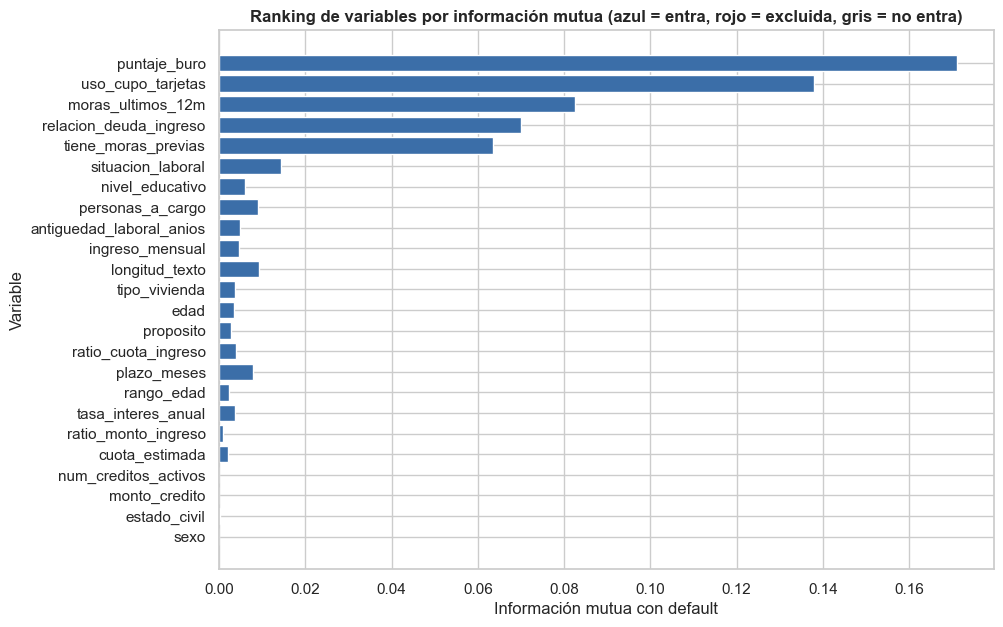

In [26]:
fig, ax = plt.subplots(figsize=(10, 7))
r = ranking.iloc[::-1]
colores = ["#d1495b" if d.startswith("Excluir") else "#3b6ea8" if d == "Entra al modelo" else "#adb5bd" for d in r["decision"]]
ax.barh(r.index, r["info_mutua"], color=colores)
ax.set_title("Ranking de variables por información mutua (azul = entra, rojo = excluida, gris = no entra)")
ax.set_xlabel("Información mutua con default"); ax.set_ylabel("Variable"); plt.show()

In [27]:
# Optimización del preprocesamiento: se guardan los límites de capping (calculados en train) para reutilizarlos
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
with open(PROCESSED_DIR / "limites_atipicos.json", "w", encoding="utf-8") as f:
    json.dump({"metodo": "capping p1-p99 calculado en train", "limites": LIMITES}, f, ensure_ascii=False, indent=2)
ranking.round(5).to_csv(PROCESSED_DIR / "ranking_variables.csv")
print("Guardados: db/processed/limites_atipicos.json y db/processed/ranking_variables.csv")

Guardados: db/processed/limites_atipicos.json y db/processed/ranking_variables.csv


**Decisión de optimización:** el conjunto de variables del paso 3 **se mantiene** (el ranking coincide con la selección de `feature_list.json`). El único cambio recomendado para `features.py` es añadir el **capping p1-p99** de las variables monetarias y ratios con los límites de `db/processed/limites_atipicos.json` (o, equivalentemente, usar modelos de árbol, que son robustos a atípicos). `sexo` sigue excluida y `texto_solicitud` se modela en el paso 7.

## Conclusiones

- **IA1.2 / IA1.E1:** el EDA univariado mostró fuerte asimetría en las variables monetarias; el bivariado confirmó diferencias significativas (Mann-Whitney) en buró, uso del cupo, moras, DTI, antigüedad, edad e ingreso; el multivariado mostró que los factores de riesgo se **acumulan** (desempleado + moras + buró < 600 alcanza ≈ 90 % de impago).
- **IA2.1 / IA2.2:** se aplicaron `merge`, `melt`/`pivot`, `apply`/`map`, `cut`/`qcut`, `groupby` con varias agregaciones y encadenamiento con `assign` y `pipe`, más el equivalente en dplyr.
- **IA2.3:** visualizaciones con **Matplotlib** (panel de subplots), **Seaborn** (heatmap, pairplot, violinplot) y **plotnine/ggplot2** (boxplots y barras con `facet_wrap`).
- **IA2.E1:** los 5 hallazgos: el historial crediticio (buró y moras) domina, el uso del cupo y el DTI anticipan el impago, la estabilidad laboral protege, monto/plazo/tasa no discriminan por sí solos y las variables sensibles aportan poco (salvo la edad, que se audita).
- **IA2.5:** atípicos detectados con IQR y z-score y tratados con **capping p1-p99** sin eliminar filas; la asimetría cae y Pearson se acerca a Spearman.
- **IA2.4:** estandarización y normalización aplicadas; el PCA reparte la varianza en muchas componentes y su proyección 2D no separa las clases, por lo que se usa solo para visualizar.
- **IA1.E2 / IA2.E2 · Variables más relevantes:** `puntaje_buro`, `uso_cupo_tarjetas`, `moras_ultimos_12m` / `tiene_moras_previas`, `relacion_deuda_ingreso`, `situacion_laboral`, `nivel_educativo`, `antiguedad_laboral_anios` y `edad`. Se mantiene la lista de `feature_list.json` y se recomienda incorporar el capping en `features.py`.